# Notebook 3: Current status of the trajectory test

**Goal.** Find patient clonotypes whose abundance changes over time more than clonotypes of healthy people do.

**How.** Healthy donors define what "neutral" looks like (the *null*). Each patient clonotype is tested against that null, and
the whole procedure is first checked on healthy donors that were left out of the null (leave-one-donor-out, LODO): on a healthy
person, every discovery is a false one.

**Status at a glance** (run of 16 Nov 2026; the tables below recompute everything):

| | |
|---|---|
| Null | 4 healthy donors (HDBR01, 02, 03, 06; 1 M PBMC, as the patients) |
| Main test | truncated negative binomial, trend over time; hurdle model as sensitivity check |
| Calibration | held-out healthy donors: **0 false discoveries**; false-positive rate at p < 0.05 of 0.2–5.6 % |
| Patients | 6 patients (BR054 set aside), swap-corrected labels |
| Result | **tens to hundreds of non-neutral clonotypes per patient** (8–383; truncated NB), most of them transient |

## 1. Setup and data
* **Donors:** the four HDBR donors after sample QC. They are the null.
* **Patients:** the swap-corrected data (`patients_clono_swapped`: BR032 day 0 and BR037 day 28 exchanged back), after
  sample QC. BR054 is set aside (possible data-collection issue).
* **Depth correction:** each sample gets an effective library size $L_t = D_t \times s_t$ ($D_t$ in-frame reads, $s_t$
  median-of-ratios size factor).

In [14]:
import sys
sys.path.insert(0, '..')

import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize
from scipy.special import gammaln

from tcr_pipeline import data_io
from tcr_pipeline.normalization import tmm_normalize
from tcr_pipeline.data_io import load_group, sample_qc, drop_failed_samples
from tcr_pipeline import nb_glm as nb
from tcr_pipeline import nb_checks as chk

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
RESULTS = Path('nb_results'); RESULTS.mkdir(exist_ok=True)

DONOR_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']
GREY, INK = '#8a8984', '#3d3c39'
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6,
    'axes.edgecolor': GREY, 'axes.labelcolor': INK, 'xtick.color': '#52514e',
    'ytick.color': '#52514e', 'lines.linewidth': 1.6, 'lines.markersize': 5,
    'legend.frameon': False, 'font.size': 9.5, 'axes.titlesize': 10})
short = chk.short
CAP = [{'selector': 'caption', 'props': 'caption-side: top; text-align: left; font-weight: bold;'}]

In [15]:
# ---- donors (null) ----
healthy_df = load_group('donors', with_D_t=True, with_freq=True)
d_qc = drop_failed_samples(healthy_df, sample_qc(healthy_df))
d_qc = tmm_normalize(d_qc)
d_qc = nb.attach_size_factor_offset(d_qc)                    # lib = L_t = D_t * size factor
NULL_DONORS = [p for p in sorted(d_qc['patient'].unique()) if str(p).startswith('HDBR')]
COLOR = dict(zip(NULL_DONORS, DONOR_COLORS))

# ---- patients (swap-corrected, contamination-cleaned) ----
data_io.ROOTS['patients_clean'] = Path('../data/patients_clono_clean/')
PATIENT_GROUP = 'patients_clean'
EXCLUDE_PATIENTS = []                                   # BR054 back in
DROP_SAMPLES = {('BR054', 141)}                         # another person's library: always out
PUT_BACK = {('BR052', 164), ('BR052', 192)}             # failed QC, put back on purpose
RUN_TAG = 'patients_clean__BR054-in__BR052-d164-d192-in'  # names the saved results of this sample set

patients_df = load_group(PATIENT_GROUP, with_D_t=True, with_freq=True)
qc = sample_qc(patients_df)
qkey = list(zip(qc['patient'].astype(str), qc['day'].astype(int)))
qc['drop'] = [(k in DROP_SAMPLES) or (dr and k not in PUT_BACK) for k, dr in zip(qkey, qc['drop'])]
p_qc = drop_failed_samples(patients_df, qc)

# size factors from the QC-passing samples only; put-back samples get size factor 1 (offset = D_t):
# the reference clonotypes are almost all absent from them, so median-of-ratios cannot be computed there
back = np.array([k in PUT_BACK for k in zip(p_qc['patient'].astype(str), p_qc['day'].astype(int))])
p_qc = pd.concat([nb.attach_size_factor_offset(p_qc[~back]),
                  p_qc[back].assign(size_factor=1.0, lib=lambda d: d['D_t'].astype(float))], ignore_index=True)
PATIENTS = [p for p in sorted(p_qc['patient'].astype(str).unique())
            if not any(p.startswith(e) for e in EXCLUDE_PATIENTS)]

sf = p_qc.groupby(['patient', 'day'], observed=True)[['D_t', 'size_factor', 'lib']].first().reset_index()
sf['note'] = ['put back (failed QC), size factor 1' if (str(p), int(d)) in PUT_BACK else ''
              for p, d in zip(sf['patient'], sf['day'])]
display(sf[sf['patient'].astype(str).isin(PATIENTS)].set_index(['patient', 'day'])
        .style.format({'D_t': '{:,.0f}', 'size_factor': '{:.3f}', 'lib': '{:,.0f}'}))

samples = lambda df, who: (df[df['patient'].astype(str).isin([str(w) for w in who])]
                           .groupby('patient', observed=True)['day'].unique().apply(sorted))
display(pd.concat({'null donor': samples(d_qc, NULL_DONORS), 'patient': samples(p_qc, PATIENTS)})
        .rename('days (QC-passed samples)').to_frame())

days (QC-passed samples)
           patient                                         
null donor HDBR01_SEQTR_ReSeq              [0, 21, 42, 126]
           HDBR02_SEQTR_ReSeq                   [0, 48, 71]
           HDBR03_SEQTR_ReSeq           [0, 21, 35, 66, 84]
           HDBR06_SEQTR_ReSeq                  [0, 82, 105]
patient    BR032                 [0, 26, 47, 110, 187, 425]
           BR037                [0, 28, 119, 189, 218, 364]
           BR046                [0, 18, 120, 194, 222, 372]
           BR048                [0, 22, 112, 161, 212, 371]
           BR052                 [0, 18, 87, 164, 192, 348]
           BR054                      [0, 19, 68, 187, 327]
           NOUS_18_SEQTR       [0, 24, 47, 54, 77, 96, 194]

## 2. The model in four ingredients

**(1) Counts: negative binomial with a depth offset.** For clonotype $c$ in sample $t$,

$$X_{ct} \sim \text{NB}(\mu_{ct}, \phi), \qquad \operatorname{Var}(X_{ct}) = \mu_{ct} + \mu_{ct}^2/\phi, \qquad
\log \mu_{ct} = \beta_c + \log s_t .$$

$\beta_c$ is the clonotype's level, $s_t$ the sample's relative depth (offset), and $\phi$ the noise: **small $\phi$ = noisy**.

**(2) Inner loop: each clonotype's level is re-fitted at every step.** Whenever a shared parameter is tried (a value of $\phi$,
the zero-part parameters, or the trend), every clonotype's $\beta_c$ is re-optimized by a few Newton steps, all clonotypes at
once (profile likelihood). The shared parameters are therefore always judged at the best level for each clonotype.

**(3) Noise $\phi$, learned from the donors only.**
* Fitted on donor clonotypes detected in **every** sample, so the likelihood is **zero-truncated** (they were selected for
  having at least one read everywhere).
* With the **Cox–Reid adjustment**, which corrects the bias from estimating one level per clonotype (without it, $\phi$ comes
  out too large, i.e. the noise is underestimated).
* Per bin of abundance, giving a **trend $\phi(m)$**, using clonotypes with frequency $f \ge 10^{-5}$ only.
* The null is the **pointwise minimum over the four donors**: at each abundance, the noisiest donor.

**(4) Zeros.** Clonotypes go missing far more often than the NB predicts (dropouts), so zeros are not taken at face value.
* **Truncated NB (main test):** zeros carry no information; only the counts when present are used,
  $P(X = k \mid X > 0) = \text{NB}(k)/(1 - \text{NB}(0))$.
* **Hurdle (sensitivity):** a zero has its own probability $\pi(f_c)$, with $\text{logit}\,\pi = a + b \log(f_c/10^{-5})$,
  fitted on the donors; counts when present follow the truncated NB. The likelihood is conditioned on the clonotype being
  detected in at least 2 samples (the selection we apply).

**The test.** Per clonotype, a constant level (H0) against a log-linear trend in time (H1),
$\beta_{ct} = \alpha_c + \gamma_c \tau_t$. The likelihood-ratio statistic is compared with $\chi^2_1$. Only clonotypes with
$f \ge 10^{-5}$ enter the multiple-testing correction (Benjamini–Hochberg, FDR 10 %): rarer ones have too little data to show a
trend, and only dilute the correction.

In [16]:
# ---- settings ----
MIN_DET = 2                  # clonotypes seen in >= 2 samples are tested (likelihood conditioned on it)
M_MIN_PHI = 10               # φ fit: mean normalized count >= this ...
F_MIN_PHI = 1e-5             # ... and frequency >= this
N_PHI_BINS = 8               # abundance bins for the φ trend
PHI_BOUNDS = (np.log(1e-2), np.log(1e4))
PHI_POOL = 'min'             # null φ = pointwise minimum over the donors
F_REF = 1e-5                 # reference frequency of the hurdle's zero part
F_MIN_TEST = 1e-5            # only clonotypes with f >= this enter BH
Q_MAX = 0.10                 # FDR
LODO_SUB_F, LODO_SUB_RATE, LODO_SEED = 1e-5, 0.15, 0   # zero-part fits: all clonotypes f >= 1e-5, 15 % of the rest
X0_LOGIT = np.array([-0.5, -0.2])
REFIT_LODO = False           # False: reuse saved LODO results if present
REFIT_PATIENTS = False       # False: reuse saved patient results if present
PHI_TAG = f'phi-{PHI_POOL}-fmin{F_MIN_PHI:g}'
slug = lambda lab: lab.replace(' ', '_').replace('/', '')

In [17]:
# ---- (3) φ: zero-truncated NB, one φ, Cox–Reid; clonotype levels profiled by Newton (inner loop) ----
def _profile_trunc(X, s, phi, n_iter=30, h_=1e-4):
    def score(beta):
        mu = np.exp(beta)[:, None] * s[None, :]
        log_p0 = -phi * np.log1p(mu / phi)
        return (phi * (X - mu) / (phi + mu) - phi * mu / (phi + mu) / np.expm1(-log_p0)).sum(1)
    beta = np.log(X.sum(1) / s.sum())
    for _ in range(n_iter):
        S = score(beta)
        H = (score(beta + h_) - score(beta - h_)) / (2 * h_)
        step = np.clip(-S / np.minimum(H, -1e-8), -1, 1)
        beta = beta + step
        if np.max(np.abs(step)) < 1e-6:
            break
    return beta, -H

def negll_trunc(log_phi, X, s):
    phi = np.exp(log_phi)
    beta, info = _profile_trunc(X, s, phi)
    mu = np.exp(beta)[:, None] * s[None, :]
    log_p0 = -phi * np.log1p(mu / phi)
    ll = (gammaln(X + phi) - gammaln(phi) - gammaln(X + 1) + log_p0
          + X * np.log(mu / (phi + mu)) - np.log(-np.expm1(log_p0))).sum()
    return -(ll - 0.5 * np.log(np.maximum(info, 1e-12)).sum())          # Cox–Reid adjustment

def phi_trend(X, s, m_min):
    '''φ per equal-count bin of mean count m (clonotypes detected in every sample, m >= m_min), interpolated in log m.'''
    Xc = X[(X > 0).all(1)]
    m = (Xc / s).mean(1)
    Xc, m = Xc[m >= m_min], m[m >= m_min]
    edges = np.quantile(np.log(m), np.linspace(0, 1, N_PHI_BINS + 1))
    idx = np.clip(np.digitize(np.log(m), edges[1:-1]), 0, N_PHI_BINS - 1)
    lm, lp = [], []
    for k in range(N_PHI_BINS):
        sel = idx == k
        if sel.sum() < 50:
            continue
        r = optimize.minimize_scalar(lambda q: negll_trunc(q, Xc[sel], s), bounds=PHI_BOUNDS,
                                     method='bounded', options={'xatol': 1e-3})
        if PHI_BOUNDS[0] + 0.05 < r.x < PHI_BOUNDS[1] - 0.05:
            lm.append(np.log(m[sel]).mean())
            lp.append(r.x)
    lm, lp = np.array(lm), np.array(lp)
    return (lambda mm: np.exp(np.interp(np.log(np.maximum(mm, 1e-12)), lm, lp))), np.exp(lm), np.exp(lp)

def count_matrix(df, p):
    '''Clonotypes x samples raw counts (0 = not detected), days, effective library size per sample.'''
    d_p = df[df['patient'] == p]
    Xdf = d_p.pivot(index='clono', columns='day', values='count').fillna(0)
    L = d_p.groupby('day', observed=True)['lib'].first().reindex(Xdf.columns).to_numpy(float)
    return Xdf, L

In [18]:
# ---- (4) likelihoods: truncated NB, hurdle, plain NB (for contrast); conditioned on >= MIN_DET detections ----
def detection_dist(q):
    '''P(number of detections = k), k = 0..T, per row of detection probabilities q (Poisson-binomial).'''
    n, T = q.shape
    dist = np.zeros((n, T + 1))
    dist[:, 0] = 1.0
    for t in range(T):
        new = dist * (1 - q[:, [t]])
        new[:, 1:] += dist[:, :-1] * q[:, [t]]
        dist = new
    return dist

def zero_logit(x, theta):
    '''log π and log(1 − π) with logit π = a + b x.'''
    eta = theta[0] + theta[1] * x
    return -np.logaddexp(0, -eta), -np.logaddexp(0, eta)

class ZeroModel:
    '''Clonotypes x samples counts with a per-clonotype φ; level β (per clonotype, or per clonotype and sample).'''
    def __init__(self, X, s, G, phi_c):
        self.X, self.s, self.pos, self.T = X, s, X > 0, X.shape[1]
        self.logG = np.log(G)
        self.ph = phi_c[:, None]
        self.const = gammaln(X + self.ph) - gammaln(self.ph) - gammaln(X + 1)
        self.n_pos = self.pos.sum(1)
        self.beta = np.log((X * self.pos).sum(1) / (s[None, :] * self.pos).sum(1))
        self.w = np.ones(len(X))

    def log_f(self, beta):
        return beta - self.logG

    def _common(self, beta, theta):
        b2 = beta if beta.ndim == 2 else beta[:, None]
        mu = np.exp(b2) * self.s[None, :]
        log_pi, log_1mpi = zero_logit(self.log_f(b2) - np.log(F_REF), theta)
        log_nb0 = -self.ph * np.log1p(mu / self.ph)
        log_nbk = self.const + self.X * np.log(mu / (self.ph + mu)) + log_nb0     # log NB(x)
        return mu, log_pi, log_1mpi, log_nb0, log_nbk

    def clone_ll(self, beta, theta):
        log_zero, log_det, ll_pos = self.parts(beta, theta)
        ll = np.where(self.pos, ll_pos, log_zero).sum(1)
        p_sel = detection_dist(np.exp(log_det))[:, MIN_DET:].sum(1)                # P(K >= MIN_DET)
        return ll - np.log(np.clip(p_sel, 1e-300, None))

    def profile(self, theta, n_iter=10, h_=1e-3):
        '''Inner loop: Newton steps on every clonotype's level β_c at fixed shared parameters.'''
        beta = self.beta.copy()
        for _ in range(n_iter):
            l0, lp_, lm_ = (self.clone_ll(beta + d, theta) for d in (0.0, h_, -h_))
            g, H = (lp_ - lm_) / (2 * h_), (lp_ - 2 * l0 + lm_) / h_**2
            step = np.clip(-g / np.minimum(H, -1e-6), -1, 1)
            beta = beta + step
            if np.max(np.abs(step)) < 1e-5:
                break
        self.beta = beta
        return beta

class TruncNB(ZeroModel):
    '''Zeros carry no information: counts when present follow the zero-truncated NB.'''
    def parts(self, beta, theta):
        mu, _, _, log_nb0, log_nbk = self._common(beta, theta)
        z = np.zeros_like(log_nbk)
        return z, z, log_nbk - np.log(-np.expm1(log_nb0))

class Hurdle(ZeroModel):
    '''P(0) = π(f);  P(k) = (1 − π) truncated NB(k), k >= 1.'''
    def parts(self, beta, theta):
        mu, log_pi, log_1mpi, log_nb0, log_nbk = self._common(beta, theta)
        shape = np.broadcast_shapes(log_pi.shape, self.X.shape)
        return (np.broadcast_to(log_pi, shape), np.broadcast_to(log_1mpi, shape),
                log_1mpi + log_nbk - np.log(-np.expm1(log_nb0)))

class PlainNB(ZeroModel):
    '''For contrast only: zeros taken as ordinary NB zeros.'''
    def parts(self, beta, theta):
        mu, _, _, log_nb0, log_nbk = self._common(beta, theta)
        return log_nb0, np.log(-np.expm1(log_nb0)), log_nbk

MODELS = {'truncated NB (zeros ignored)': (TruncNB, False),
          'hurdle / logit': (Hurdle, True),
          'plain NB (zeros = NB zeros)': (PlainNB, False)}       # (class, has a zero part to fit)

In [19]:
# ---- fitting helpers: null φ, zero part, trend test ----
def pooled_phi_fn(train):
    '''Null φ trend from the training donors: pointwise minimum (PHI_POOL = 'min') or mean of log φ.'''
    m_max = max(DONOR_DATA[p]['phi_nodes'][0].max() for p in train)
    grid = np.logspace(np.log10(M_MIN_PHI), np.log10(m_max), 40)
    L = np.array([np.log(DONOR_DATA[p]['phi_fn'](grid)) for p in train])
    lphi = L.min(axis=0) if PHI_POOL == 'min' else L.mean(axis=0)
    return lambda mm: np.exp(np.interp(np.log(np.maximum(mm, 1e-12)), np.log(grid), lphi))

def build_model(cls, d, phi_fn, sub=False, rng=None):
    '''Model for one person; sub=True keeps all clonotypes f >= LODO_SUB_F and a weighted 15 % of the rest.'''
    X, s, G = d['X'], d['s'], d['G']
    pos = X > 0
    m_present = (X * pos).sum(1) / (s[None, :] * pos).sum(1)
    phi_c = phi_fn(m_present)
    w = np.ones(len(X))
    if sub:
        f_p = m_present / G
        keep = (f_p >= LODO_SUB_F) | (rng.random(len(X)) < LODO_SUB_RATE)
        X, phi_c, w = X[keep], phi_c[keep], np.where(f_p[keep] >= LODO_SUB_F, 1.0, 1.0 / LODO_SUB_RATE)
    md = cls(X, s, G, phi_c)
    md.w = w
    return md

def fit_theta(models):
    '''Zero-part parameters (a, b), fitted jointly on several donors (inner loop on every clonotype's level).'''
    obj = lambda th: sum(-(m.w * m.clone_ll(m.profile(th), th)).sum() for m in models)
    return optimize.minimize(obj, X0_LOGIT, method='Nelder-Mead',
                             options={'xatol': 1e-3, 'fatol': 1e-2, 'maxiter': 300}).x

def fit_trend(md, theta, tau, beta0, n_iter=20, h=1e-3):
    '''H1: per-clonotype log-linear trend (α_c, γ_c), vectorized 2-D Newton with backtracking.'''
    ll = lambda a, g: md.clone_ll(a[:, None] + g[:, None] * tau[None, :], theta)
    A, Gm = beta0.copy(), np.zeros_like(beta0)
    f0 = ll(A, Gm)
    for _ in range(n_iter):
        fa_p, fa_m, fg_p, fg_m = ll(A + h, Gm), ll(A - h, Gm), ll(A, Gm + h), ll(A, Gm - h)
        fpp, fmm = ll(A + h, Gm + h), ll(A - h, Gm - h)
        ga, gg = (fa_p - fa_m) / (2 * h), (fg_p - fg_m) / (2 * h)
        Haa, Hgg = (fa_p - 2 * f0 + fa_m) / h**2, (fg_p - 2 * f0 + fg_m) / h**2
        Hag = (fpp - fa_p - fg_p + 2 * f0 - fa_m - fg_m + fmm) / (2 * h**2)
        det = Haa * Hgg - Hag**2
        ok = (Haa < 0) & (det > 0)
        da = np.where(ok, -(Hgg * ga - Hag * gg) / np.where(ok, det, 1), 0.1 * ga)
        dg = np.where(ok, -(-Hag * ga + Haa * gg) / np.where(ok, det, 1), 0.1 * gg)
        da, dg = np.clip(da, -1, 1), np.clip(dg, -1, 1)
        for _ in range(5):
            f_new = ll(A + da, Gm + dg)
            bad = f_new < f0 - 1e-9
            if not bad.any():
                break
            da, dg = np.where(bad, da / 2, da), np.where(bad, dg / 2, dg)
        f_new = ll(A + da, Gm + dg)
        move = f_new >= f0 - 1e-9
        A, Gm, f0 = np.where(move, A + da, A), np.where(move, Gm + dg, Gm), np.where(move, f_new, f0)
        if max(np.abs(da[move]).max(initial=0), np.abs(dg[move]).max(initial=0)) < 1e-5:
            break
    return A, Gm, f0

def trend_test(md, theta, days):
    '''Likelihood-ratio test, constant level vs log-linear trend in time (χ² with 1 df).'''
    beta0 = md.profile(theta, n_iter=30)
    ll0 = md.clone_ll(beta0, theta)
    tau = (days - days.mean()) / 100.0
    _, gam, ll1 = fit_trend(md, theta, tau, beta0)
    p = stats.chi2.sf(np.maximum(2 * (ll1 - ll0), 0.0), 1)
    return pd.DataFrame({'f': np.exp(md.log_f(beta0)), 'K': md.n_pos, 'T': md.T,
                         'first missing': ~md.pos[:, 0], 'last missing': ~md.pos[:, -1], 'gamma': gam, 'p': p})

bh = lambda p: np.asarray(nb.bh_correct(pd.Series(np.asarray(p, dtype=float))), dtype=float)

def with_filter(df):
    '''Clonotypes with f >= F_MIN_TEST, BH recomputed within them (per person).'''
    d = df[df['f'] >= F_MIN_TEST].copy()
    d['q_f'] = bh(d['p']) if len(d) else np.array([])
    return d

## 3. The noise trend $\phi(m)$ from the donors
One curve per donor (truncated NB + Cox–Reid, clonotypes detected in every sample with $f \ge 10^{-5}$). The thick line is
the null used for the patients: at each abundance, the noisiest donor.

,samples,clonotypes tested (≥2 det.),φ at lowest bin,φ at highest bin
donor,,,,
HDBR01,4,90868,1.15,2.53
HDBR02,3,68048,1.30,4.11
HDBR03,5,159850,1.52,4.26
HDBR06,3,58818,1.03,2.98


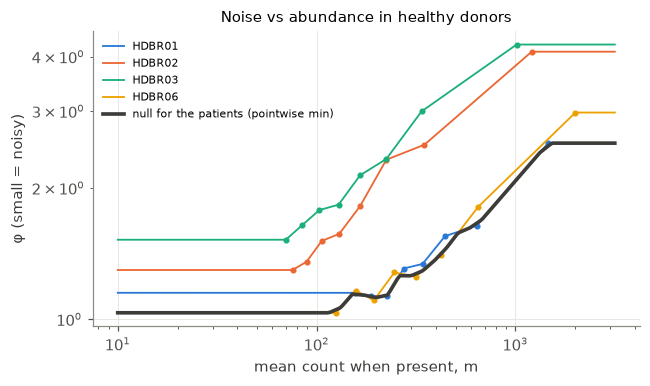

In [20]:
DONOR_DATA, rows = {}, []
for p in NULL_DONORS:
    Xdf, L = count_matrix(d_qc, p)
    X, days = Xdf.to_numpy(float), Xdf.columns.to_numpy()
    G = np.exp(np.log(L).mean())
    s = L / G
    m_min = max(M_MIN_PHI, F_MIN_PHI * G)
    phi_fn, nodes_m, nodes_phi = phi_trend(X, s, m_min)
    keep = (X > 0).sum(1) >= MIN_DET
    DONOR_DATA[p] = dict(X=X[keep], days=days, s=s, G=G, phi_fn=phi_fn, phi_nodes=(nodes_m, nodes_phi))
    rows.append({'donor': short(p), 'samples': len(days), f'clonotypes tested (≥{MIN_DET} det.)': int(keep.sum()),
                 'φ at lowest bin': nodes_phi[0], 'φ at highest bin': nodes_phi[-1]})
display(pd.DataFrame(rows).set_index('donor').round(2))

mm = np.logspace(1, 3.5, 200)
fig, ax = plt.subplots(figsize=(6, 3.6))
for p in NULL_DONORS:
    ax.plot(*DONOR_DATA[p]['phi_nodes'], 'o', ms=3, color=COLOR[p])
    ax.plot(mm, DONOR_DATA[p]['phi_fn'](mm), lw=1.2, color=COLOR[p], label=short(p))
PHI_NULL = pooled_phi_fn(NULL_DONORS)
ax.plot(mm, PHI_NULL(mm), color=INK, lw=2.4, label='null for the patients (pointwise min)')
ax.set(xscale='log', yscale='log', xlabel='mean count when present, m', ylabel='φ (small = noisy)',
       title='Noise vs abundance in healthy donors')
ax.legend(fontsize=7); fig.tight_layout(); plt.show()

## 4. Calibration on held-out healthy donors (LODO)
For each donor in turn: the null ($\phi$ trend and, for the hurdle, the zero part) is built from the **other three**, and every
clonotype of the held-out donor is tested exactly as a patient would be. A healthy donor should give about 5 % of p-values below
0.05 and **no discoveries** after the FDR correction.

The plain NB, which takes every zero as an ordinary NB zero, is included only to show why the zeros cannot be used as they are.

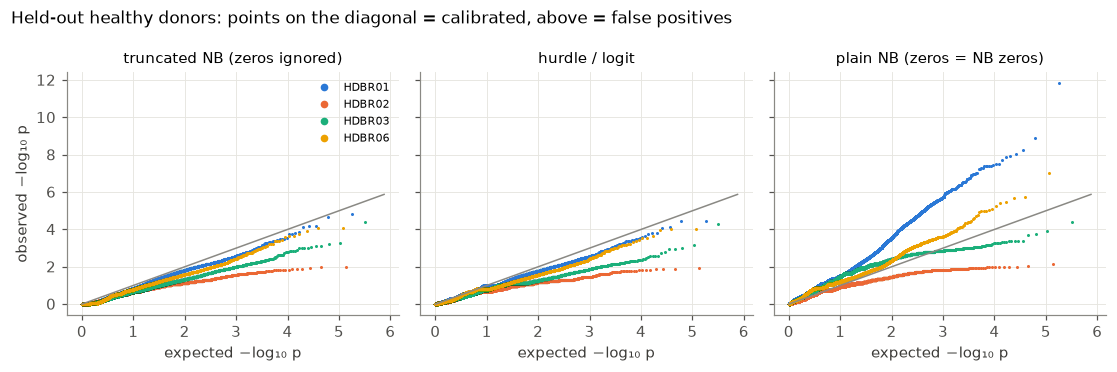

In [21]:
def lodo(cls, label, has_zero_part):
    rng = np.random.default_rng(LODO_SEED)
    out = []
    for held in NULL_DONORS:
        t0 = time.time()
        train = [p for p in NULL_DONORS if p != held]
        phi_held = pooled_phi_fn(train)
        theta = (fit_theta([build_model(cls, DONOR_DATA[p], DONOR_DATA[p]['phi_fn'], sub=True, rng=rng) for p in train])
                 if has_zero_part else np.zeros(2))
        md = build_model(cls, DONOR_DATA[held], phi_held)
        out.append(trend_test(md, theta, DONOR_DATA[held]['days'].astype(float)).assign(donor=short(held)))
        print(f'{label}: {short(held)} done in {(time.time() - t0) / 60:.1f} min', flush=True)
    return pd.concat(out, ignore_index=True)

LODO = {}
for lab, (cls, has_zero_part) in MODELS.items():
    f = RESULTS / f'lodo__{PHI_TAG}__{slug(lab)}.parquet'
    if f.exists() and not REFIT_LODO:
        LODO[lab] = pd.read_parquet(f)
    else:
        LODO[lab] = lodo(cls, lab, has_zero_part)
        LODO[lab].to_parquet(f)

rows = []
for lab, df in LODO.items():
    for donor, d in df.groupby('donor'):
        k = with_filter(d)
        rows.append({'model': lab, 'donor': donor,
                     'clonotypes (all)': len(d), 'FPR p<0.05, all (%)': 100 * (d['p'] < 0.05).mean(),
                     f'clonotypes f ≥ {F_MIN_TEST:g}': len(k), 'FPR p<0.05, filtered (%)': 100 * (k['p'] < 0.05).mean(),
                     f'discoveries, BH q<{Q_MAX} (all false)': int((k['q_f'] < Q_MAX).sum())})
display(pd.DataFrame(rows).set_index(['model', 'donor']).style
        .format({'clonotypes (all)': '{:,.0f}', f'clonotypes f ≥ {F_MIN_TEST:g}': '{:,.0f}',
                 'FPR p<0.05, all (%)': '{:.1f}', 'FPR p<0.05, filtered (%)': '{:.1f}'})
        .set_caption('Held-out healthy donors. Wanted: FPR around or below 5 %, and 0 discoveries').set_table_styles(CAP))

fig, axes = plt.subplots(1, len(LODO), figsize=(3.4 * len(LODO), 3.4), sharex=True, sharey=True)
for ax, (lab, df) in zip(axes, LODO.items()):
    for p in NULL_DONORS:
        pv = np.sort(df.loc[df['donor'] == short(p), 'p'].to_numpy())
        ex = (np.arange(1, len(pv) + 1) - 0.5) / len(pv)
        ax.plot(-np.log10(ex), -np.log10(np.clip(pv, 1e-300, None)), '.', ms=2, color=COLOR[p], label=short(p))
    lim = -np.log10(0.5 / max(len(df), 1))
    ax.plot([0, lim], [0, lim], color=GREY, lw=1)
    ax.set(title=lab, xlabel='expected −log₁₀ p')
axes[0].set_ylabel('observed −log₁₀ p')
axes[0].legend(fontsize=7, markerscale=4)
fig.suptitle('Held-out healthy donors: points on the diagonal = calibrated, above = false positives', x=0.01, ha='left')
fig.tight_layout(); plt.show()

**Reading.** The truncated NB and the hurdle give no discoveries in any held-out donor, and their p-values lie on or below the
diagonal (slightly conservative). The plain NB produces hundreds of false discoveries in some donors: zeros cannot be treated as
ordinary NB zeros. This is the evidence that the procedure below does not flag healthy-like clonotypes.

## 5. Patients
The null is now built from all four donors (pointwise-minimum $\phi$; the hurdle's zero part fitted on all four), and every
patient clonotype seen in at least 2 samples is tested. Only clonotypes with $f \ge 10^{-5}$ enter the FDR correction, the same
filter that gave no discoveries in the held-out donors.

In [22]:
PATIENT_DATA = {}
for p in PATIENTS:
    Xdf, L = count_matrix(p_qc, p)
    X = Xdf.to_numpy(float)
    keep = (X > 0).sum(1) >= MIN_DET
    G = np.exp(np.log(L).mean())
    PATIENT_DATA[p] = dict(X=X[keep], clono=Xdf.index.to_numpy()[keep], days=Xdf.columns.to_numpy(), s=L / G, G=G)

PATIENT_TEST, THETA_ALL = {}, {}
for lab, (cls, has_zero_part) in MODELS.items():
    if lab.startswith('plain'):
        continue
    f = RESULTS / f'patient_test__{PATIENT_GROUP}__{PHI_TAG}__{slug(lab)}.parquet'
    if f.exists() and not REFIT_PATIENTS:
        PATIENT_TEST[lab] = pd.read_parquet(f)
        continue
    rng = np.random.default_rng(LODO_SEED)
    theta = (fit_theta([build_model(cls, DONOR_DATA[p], DONOR_DATA[p]['phi_fn'], sub=True, rng=rng) for p in NULL_DONORS])
             if has_zero_part else np.zeros(2))
    THETA_ALL[lab] = theta
    out = []
    for p in PATIENTS:
        t0 = time.time()
        d = PATIENT_DATA[p]
        res = trend_test(build_model(cls, d, PHI_NULL), theta, d['days'].astype(float))
        res.insert(0, 'clono', d['clono'])
        res.insert(0, 'patient', short(p))
        res['q'] = bh(res['p'])
        out.append(res)
        print(f'{lab}: {short(p)} done in {(time.time() - t0) / 60:.1f} min', flush=True)
    PATIENT_TEST[lab] = pd.concat(out, ignore_index=True)
    PATIENT_TEST[lab].to_parquet(f)

display(pd.DataFrame({short(p): {'samples': len(PATIENT_DATA[p]['days']), 'days': PATIENT_DATA[p]['days'].tolist(),
                                 f'clonotypes (≥{MIN_DET} det.)': len(PATIENT_DATA[p]['X'])} for p in PATIENTS}).T)

truncated NB (zeros ignored): BR032 done in 0.7 min
truncated NB (zeros ignored): BR037 done in 0.3 min
truncated NB (zeros ignored): BR046 done in 0.8 min
truncated NB (zeros ignored): BR048 done in 1.1 min
truncated NB (zeros ignored): BR052 done in 0.4 min
truncated NB (zeros ignored): BR054 done in 0.7 min
truncated NB (zeros ignored): NOUS_18 done in 0.7 min
hurdle / logit: BR032 done in 0.8 min
hurdle / logit: BR037 done in 0.4 min
hurdle / logit: BR046 done in 1.0 min
hurdle / logit: BR048 done in 1.4 min
hurdle / logit: BR052 done in 0.5 min
hurdle / logit: BR054 done in 0.8 min
hurdle / logit: NOUS_18 done in 0.9 min


,samples,days,clonotypes (≥2 det.)
BR032,6,"[0, 26, 47, 110, 187, 425]",129214
BR037,6,"[0, 28, 119, 189, 218, 364]",57973
BR046,6,"[0, 18, 120, 194, 222, 372]",142585
BR048,6,"[0, 22, 112, 161, 212, 371]",184805
BR052,6,"[0, 18, 87, 164, 192, 348]",72935
BR054,5,"[0, 19, 68, 187, 327]",143345
NOUS_18,7,"[0, 24, 47, 54, 77, 96, 194]",108130


### Non-neutral clonotypes per patient, and the shape of their trajectories
The test looks for a trend, but the trajectories it flags are not all monotone. Each hit is described by where its peak falls:
* **transient:** the peak is at least 4× the typical level both before and after it (rises, then falls);
* otherwise **expanding** or **contracting**, by the sign of the fitted trend.

"One-sample peak" counts hits whose high level rests on a single sample (no other sample within 4× of the peak).
The shape is descriptive; it does not change the p-values.

In [23]:
FOLD = 4
SHAPE_COLOR = {'expanding': '#c0392b', 'contracting': '#2a78d6', 'transient': '#d68910'}
MAIN = 'truncated NB (zeros ignored)'
full_name = {short(p): p for p in PATIENTS}

def shape_of(x, L):
    fr = np.where(x > 0, x / L, 0.5 / L)                     # not detected = half a read at that depth
    k = int(np.argmax(fr))
    before, after = fr[:k], fr[k + 1:]
    transient = (len(before) > 0 and len(after) > 0
                 and fr[k] >= FOLD * np.median(before) and fr[k] >= FOLD * np.median(after))
    return transient, k, int((fr >= fr[k] / FOLD).sum())

HITS = []
for lab, res in PATIENT_TEST.items():
    for p in PATIENTS:
        pt, d = short(p), PATIENT_DATA[p]
        L = d['s'] * d['G']
        k = with_filter(res[res['patient'] == pt])
        h = k[k['q_f'] < Q_MAX].copy()
        info = [shape_of(d['X'][r], L) for r in pd.Index(d['clono']).get_indexer(h['clono'])]
        h['shape'] = ['transient' if tr else ('expanding' if g > 0 else 'contracting')
                      for (tr, _, _), g in zip(info, h['gamma'])]
        h['peak day'] = [d['days'][i] for _, i, _ in info]
        h['samples near peak'] = [n for _, _, n in info]
        h['model'], h['tested'] = lab, len(k)
        HITS.append(h)
HITS = pd.concat(HITS, ignore_index=True)

tab = (HITS.groupby(['model', 'patient'])
           .agg(tested=('tested', 'first'), hits=('clono', 'size'),
                expanding=('shape', lambda s: (s == 'expanding').sum()),
                contracting=('shape', lambda s: (s == 'contracting').sum()),
                transient=('shape', lambda s: (s == 'transient').sum()),
                **{'one-sample peak': ('samples near peak', lambda s: (s == 1).sum())}))
tab['% of tested'] = 100 * tab['hits'] / tab['tested']
display(tab.style.format({'tested': '{:,.0f}', '% of tested': '{:.2f}'})
        .set_caption(f'Non-neutral clonotypes (f ≥ {F_MIN_TEST:g}, BH q < {Q_MAX})').set_table_styles(CAP))
HITS.to_csv(RESULTS / f'hits__{PATIENT_GROUP}__{PHI_TAG}.csv', index=False)

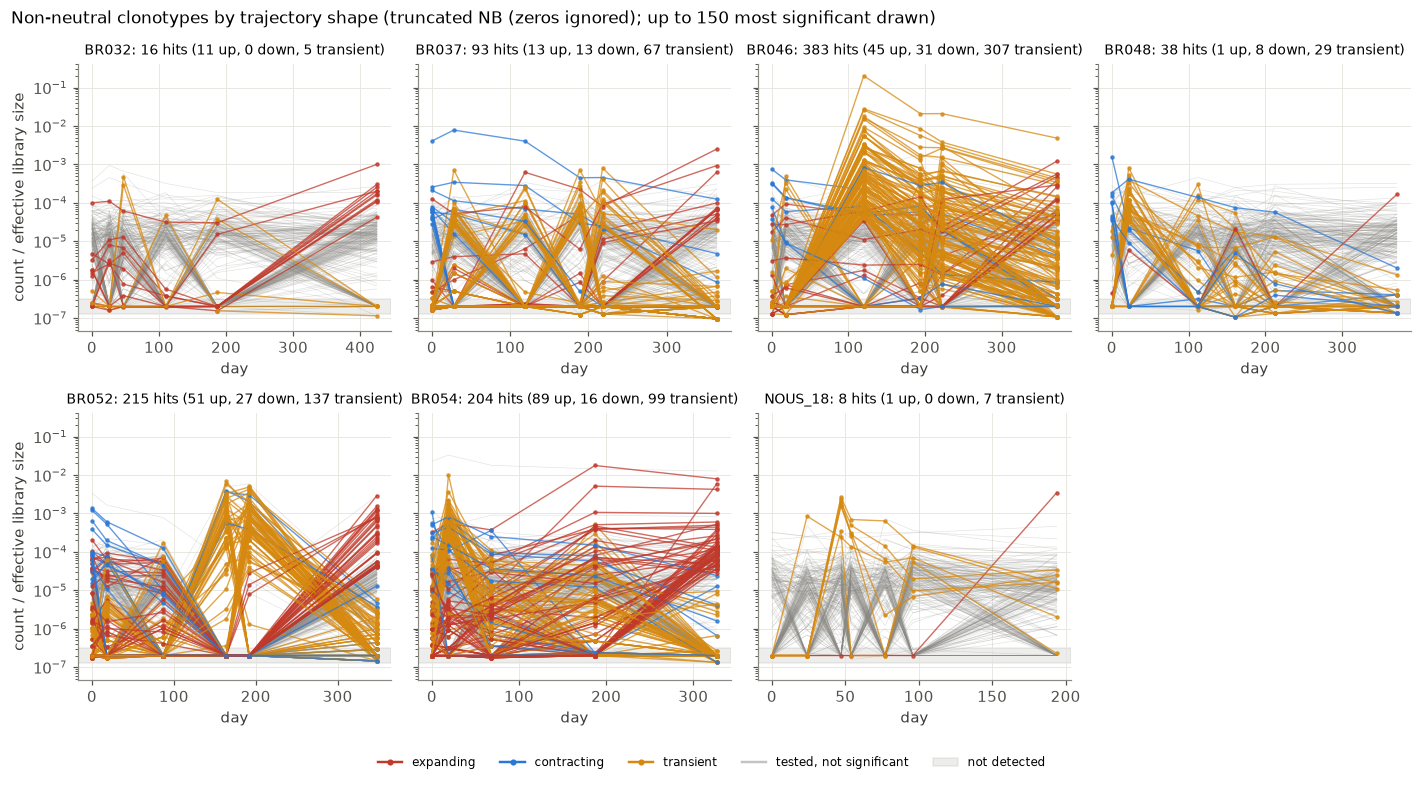

In [24]:
main = HITS[HITS['model'] == MAIN]
rng_plot = np.random.default_rng(1)
FLOOR = 2e-7
fig, axes = plt.subplots(2, int(np.ceil(len(PATIENTS) / 2)), figsize=(13, 7), sharey=True, squeeze=False)
for ax, p in zip(axes.flat, PATIENTS):
    pt, d = short(p), PATIENT_DATA[p]
    L = d['s'] * d['G']
    freq = np.where(d['X'] > 0, d['X'] / L[None, :], FLOOR)
    idx = pd.Index(d['clono'])
    k = with_filter(PATIENT_TEST[MAIN][PATIENT_TEST[MAIN]['patient'] == pt])
    bg = k.loc[k['q_f'] >= Q_MAX, 'clono'].to_numpy()
    for r in idx.get_indexer(rng_plot.choice(bg, size=min(300, len(bg)), replace=False)):
        ax.plot(d['days'], freq[r], color=GREY, lw=0.4, alpha=0.25)
    h = main[main['patient'] == pt].sort_values('q_f').head(150)
    for r, shp in zip(idx.get_indexer(h['clono']), h['shape']):
        ax.plot(d['days'], freq[r], color=SHAPE_COLOR[shp], lw=0.9, alpha=0.75, marker='o', ms=2)
    ax.axhspan(FLOOR / 1.6, FLOOR * 1.6, color=GREY, alpha=0.15)
    n = main[main['patient'] == pt]['shape'].value_counts()
    ax.set(yscale='log', xlabel='day', title=f"{pt}: {n.sum()} hits ({n.get('expanding', 0)} up, "
                                             f"{n.get('contracting', 0)} down, {n.get('transient', 0)} transient)")
    ax.title.set_fontsize(9)
for ax in axes.flat[len(PATIENTS):]:
    ax.set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel('count / effective library size')
handles = [plt.Line2D([], [], color=c, marker='o', ms=3, label=s) for s, c in SHAPE_COLOR.items()]
handles += [plt.Line2D([], [], color=GREY, alpha=0.5, label='tested, not significant'),
            plt.Rectangle((0, 0), 1, 1, color=GREY, alpha=0.15, label='not detected')]
fig.legend(handles=handles, ncol=5, fontsize=8, loc='lower center', bbox_to_anchor=(0.5, -0.02), frameon=False)
fig.suptitle(f'Non-neutral clonotypes by trajectory shape ({MAIN}; up to 150 most significant drawn)', x=0.01, ha='left')
fig.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

# 6 Clustering of the detected trayectories

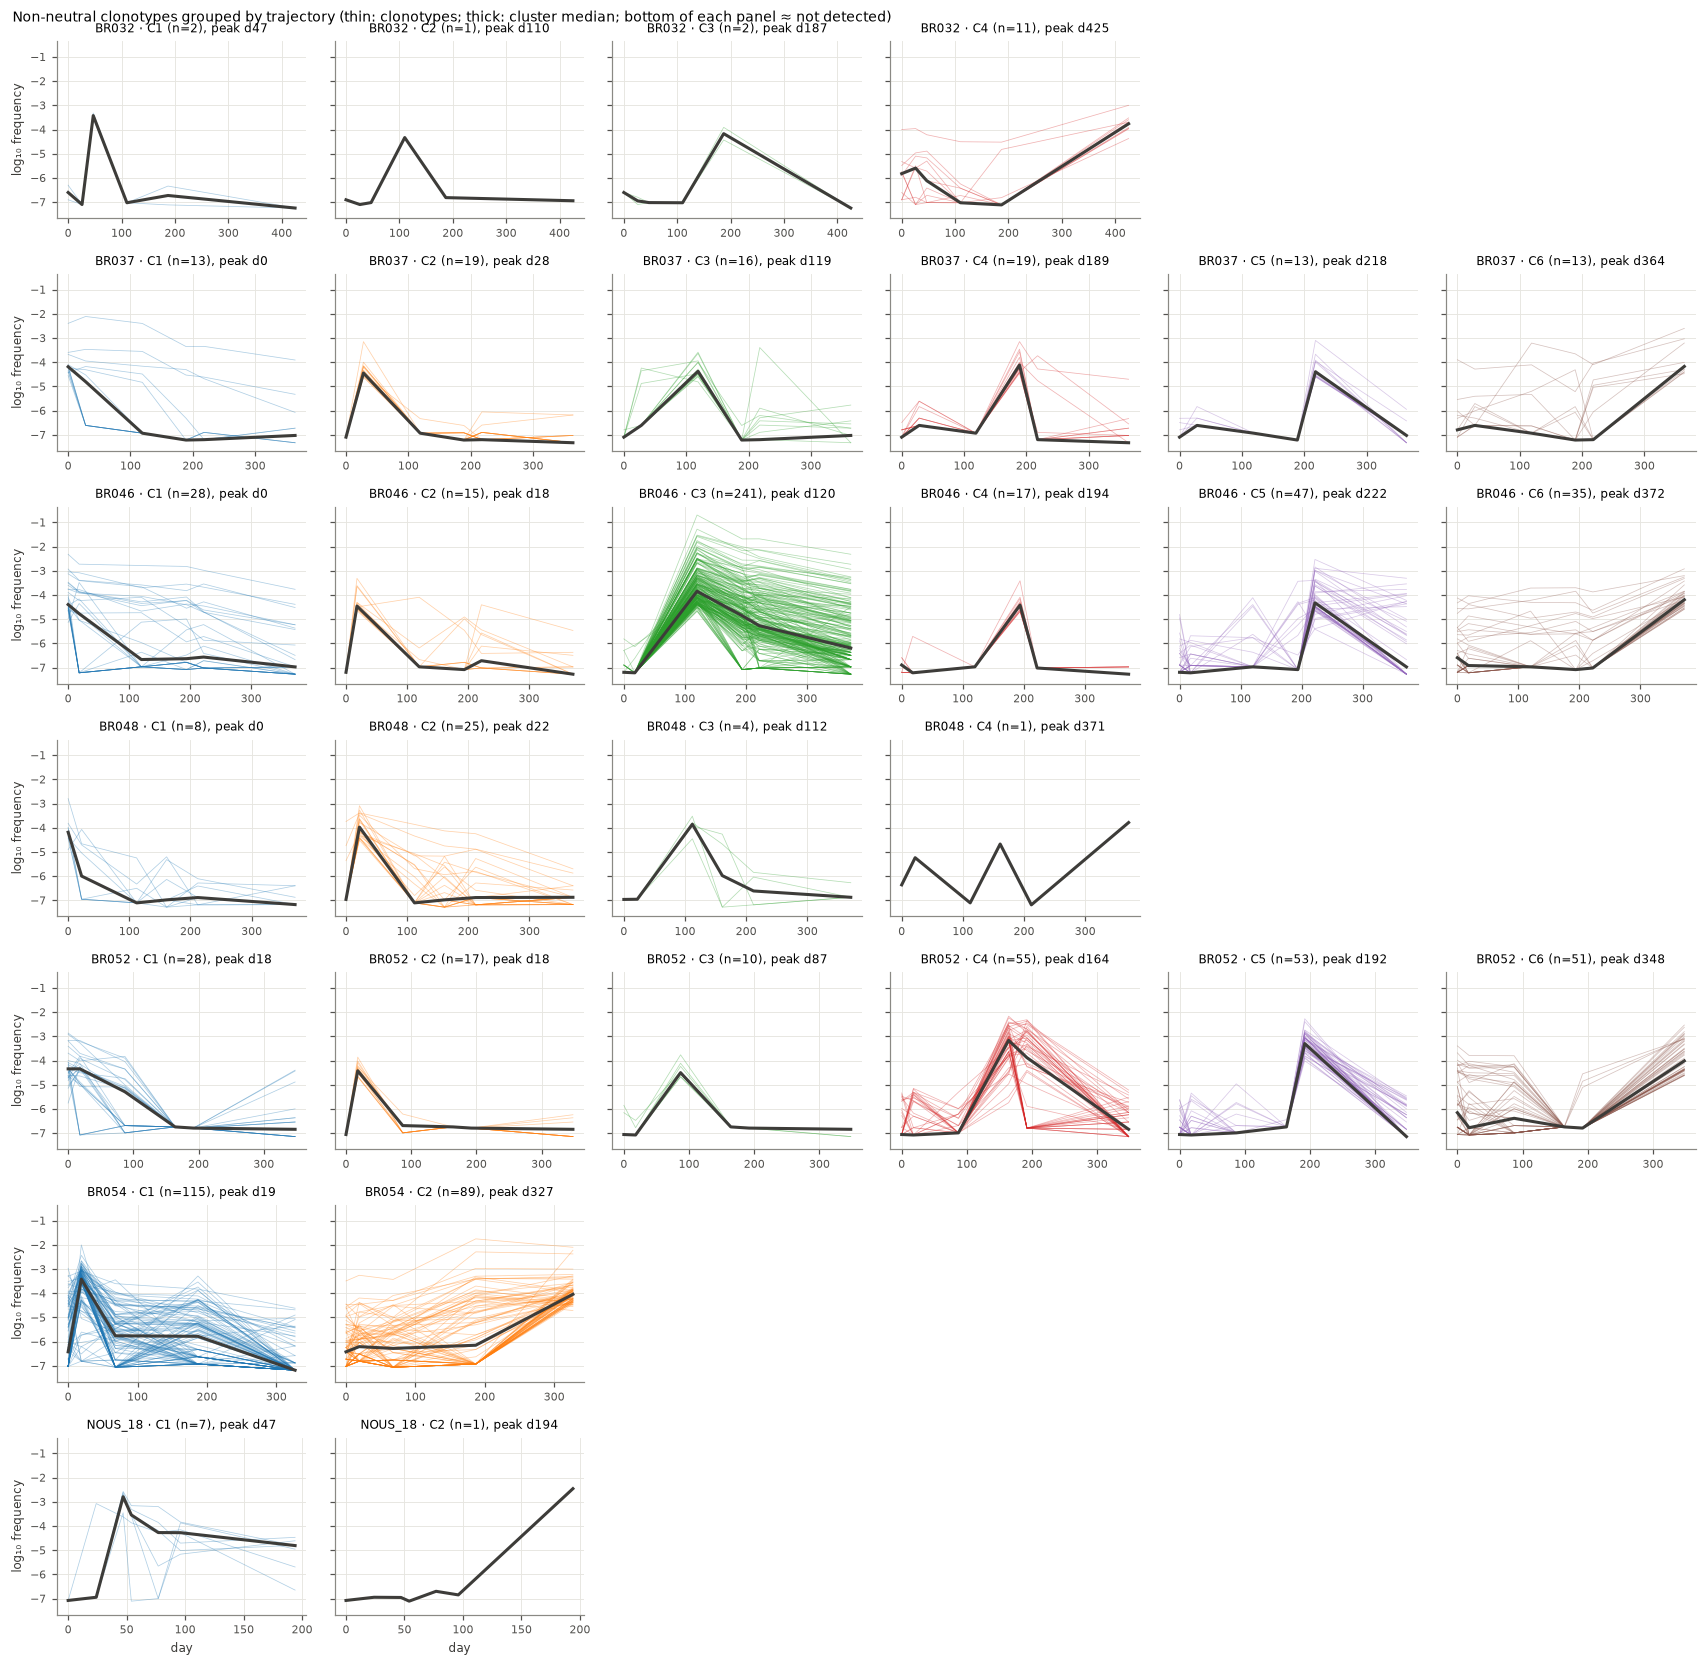

In [25]:
# Clusters of non-neutral clonotypes per patient, by trajectory shape (when they rise and fall)
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist, squareform

CLUSTER_MODEL = MAIN                 # 'hurdle / logit' to cluster the hurdle's hits instead
K_MAX, MIN_FOR_CLUSTERING = 6, 6
excl_file = RESULTS / 'BR052_d0_contaminant_like_clonotypes.csv'
EXCLUDE = {('BR052', int(c)) for c in pd.read_csv(excl_file)['clono']} if excl_file.exists() else set()

def profiles(pt, clonos):
    """log10 frequency per sample (not detected = half a read at that depth), and its per-clonotype z-score."""
    d = PATIENT_DATA[full_name[pt]]
    L = d['s'] * d['G']
    X = d['X'][pd.Index(d['clono']).get_indexer(clonos)]
    lf = np.log10(np.where(X > 0, X / L[None, :], 0.5 / L[None, :]))
    z = (lf - lf.mean(1, keepdims=True)) / np.maximum(lf.std(1, keepdims=True), 1e-9)
    return d['days'], lf, z

def silhouette(D, lab):
    s = np.zeros(len(lab))
    for i in range(len(lab)):
        same = lab == lab[i]
        if same.sum() <= 1:
            continue
        a = D[i, same].sum() / (same.sum() - 1)
        b = min(D[i, lab == l].mean() for l in np.unique(lab) if l != lab[i])
        s[i] = (b - a) / max(a, b)
    return s.mean()

def cluster(z):
    if len(z) < MIN_FOR_CLUSTERING:
        return np.ones(len(z), int), np.nan
    Zl, D = linkage(z, 'ward'), squareform(pdist(z))
    best_lab, best_s = np.ones(len(z), int), -np.inf
    for k in range(2, min(K_MAX, len(z) - 1) + 1):
        lab = fcluster(Zl, k, 'maxclust')
        if len(np.unique(lab)) == k:
            s = silhouette(D, lab)
            if s > best_s:
                best_lab, best_s = lab, s
    return best_lab, best_s

hits_c = HITS[HITS['model'] == CLUSTER_MODEL].copy()
hits_c = hits_c[[(p, int(c)) not in EXCLUDE for p, c in zip(hits_c['patient'], hits_c['clono'])]]
out, rows, PLOT = [], [], {}
for p in PATIENTS:
    pt = short(p)
    h = hits_c[hits_c['patient'] == pt].copy()
    if h.empty:
        continue
    days, lf, z = profiles(pt, h['clono'].to_numpy())
    lab, sil = cluster(z)
    order = sorted(np.unique(lab), key=lambda c: (days[np.argmax(np.median(lf[lab == c], 0))], -(lab == c).sum()))
    relabel = {c: i + 1 for i, c in enumerate(order)}           # clusters numbered by the day of their peak
    h['cluster'] = [relabel[c] for c in lab]
    out.append(h)
    PLOT[pt] = (days, lf, h['cluster'].to_numpy())
    for c in sorted(h['cluster'].unique()):
        m = h['cluster'] == c
        med = np.median(lf[m.to_numpy()], 0)
        rows.append({'patient': pt, 'cluster': c, 'clonotypes': int(m.sum()), 'silhouette': sil,
                     'peak day (median profile)': days[np.argmax(med)],
                     'fold change, peak vs lowest': 10 ** (med.max() - med.min()),
                     'shapes': ', '.join(f'{k} {v}' for k, v in h.loc[m, 'shape'].value_counts().items())})
HITS_CL = pd.concat(out, ignore_index=True)
display(pd.DataFrame(rows).set_index(['patient', 'cluster']).style
        .format({'silhouette': '{:.2f}', 'fold change, peak vs lowest': '{:.0f}x'}, na_rep='—')
        .set_caption(f'Clusters of non-neutral clonotypes ({CLUSTER_MODEL}), numbered by the day of their peak')
        .set_table_styles(CAP))

# ---- plot: one row per patient, one panel per cluster ----
n_cols = max(HITS_CL.groupby('patient')['cluster'].max())
fig, axes = plt.subplots(len(PLOT), n_cols, figsize=(2.6 * n_cols, 2.2 * len(PLOT)), sharey=True, squeeze=False)
pal = plt.get_cmap('tab10')
for r, (pt, (days, lf, lab)) in enumerate(PLOT.items()):
    for c in range(1, n_cols + 1):
        ax = axes[r, c - 1]
        m = lab == c
        if not m.any():
            ax.set_visible(False)
            continue
        for row in lf[m]:
            ax.plot(days, row, color=pal(c - 1), lw=0.5, alpha=0.35)
        ax.plot(days, np.median(lf[m], 0), color=INK, lw=2)
        ax.set_title(f'{pt} · C{c} (n={m.sum()}), peak d{days[np.argmax(np.median(lf[m], 0))]}', fontsize=8)
        ax.tick_params(labelsize=7)
        if c == 1:
            ax.set_ylabel('log₁₀ frequency', fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel('day', fontsize=8)
fig.suptitle('Non-neutral clonotypes grouped by trajectory (thin: clonotypes; thick: cluster median; '
             'bottom of each panel ≈ not detected)', x=0.01, ha='left', fontsize=9)
fig.tight_layout(); plt.show()

HITS_CL.to_csv(RESULTS / f'hits_clusters__{PATIENT_GROUP}__{PHI_TAG}.csv', index=False)

In [26]:
# ---- previous run (swapped, BR054 out, BR052 d164/d192 out) vs this run ----
old = pd.read_csv(RESULTS / f'hits__patients_swapped__{PHI_TAG}.csv')
new = HITS
key = ['model', 'patient']
cmp = pd.concat({'hits (previous)': old.groupby(key).size(), 'hits (now)': new.groupby(key).size()},
                axis=1).fillna(0).astype(int)
cmp['in both'] = [len(set(old.loc[(old['model'] == m) & (old['patient'] == p), 'clono'])
                      & set(new.loc[(new['model'] == m) & (new['patient'] == p), 'clono'])) for m, p in cmp.index]
display(cmp.style.set_caption('Non-neutral clonotypes, previous run vs now').set_table_styles(CAP))

# ---- BR052: hits lost / gained / kept, by shape and peak day ----
for lab in PATIENT_TEST:
    o = old[(old['model'] == lab) & (old['patient'] == 'BR052')]
    n = new[(new['model'] == lab) & (new['patient'] == 'BR052')]
    summ = pd.concat({'lost': o[~o['clono'].isin(n['clono'])].groupby(['shape', 'peak day']).size(),
                      'gained': n[~n['clono'].isin(o['clono'])].groupby(['shape', 'peak day']).size(),
                      'kept': n[n['clono'].isin(o['clono'])].groupby(['shape', 'peak day']).size()},
                     axis=1).fillna(0).astype(int)
    display(summ.style.set_caption(f'BR052, {lab}').set_table_styles(CAP))

## 7. Where we stand

**Validated**
* A null built only from healthy donors, with the noisiest donor's noise at every abundance.
* On held-out healthy donors, the same procedure gives **no false discoveries** (truncated NB and hurdle).
* In patients it finds tens to hundreds of non-neutral clonotypes (0.1–2.5 % of those tested), in line with published rates for
  longitudinal TCR data (0.5–1.7 % in healthy people against technical noise only, Ayestaran et al. 2022), against a stricter null.

**Open questions (next steps)**
1. **Single-sample peaks.** Most hits are high in one sample, and within a patient they peak on the same sample. This could be
   a real response caught at one visit, or a technically atypical library. Next: compare the peak samples' technical profile
   (reads per clonotype) with the donors, and if needed predict a per-sample noise level from it.
2. **Power.** The calibration shows healthy clonotypes are not flagged; it does not say how large a change must be to be
   detected. Next: a simulation with known changes added to donor clonotypes.
3. **Transient clonotypes as a tested category** (rise then fall), not only described.
4. **Data caveats.** BR052's day-0 library contains clonotypes of another sample (its contractions are suspect); BR054 is set
  aside; clonotypes below $f = 10^{-5}$ are not tested; the null rests on four donors.